Finale Bewertung – Betrugserkennung bei Strom und Gas
Team 5 (Roland, Leo, Tobias) · Meilenstein 4

Hier nutze ich zum ersten und einzigen Mal den Test-Teil. Vorher müssen die Notebooks 04 bis 08 gelaufen sein.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

from fd_utils import evaluate, lift_top

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("data")
MODEL_DIR = Path("models")

NICHT_FEATURES = ["client_id", "creation_date", "split", "target"]
TOP_ANTEIL = 0.10   # STEG kontrolliert etwa 10 %

# Name -> Zeile in cv_ergebnisse.csv
CV_ZEILEN = {
    "Baseline (LogReg)": "Baseline: LogReg (fd_cleaned)",
    "Bestes Modell (Random Forest)": "Random Forest (getunt)",
}

df = pd.read_csv(DATA_DIR / "fd_features.csv")
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")
df_test = df.merge(df_split, on="client_id", how="left").query("split == 'test'")

X_test = df_test.drop(columns=NICHT_FEATURES)
y_test = df_test["target"]

baseline = joblib.load(MODEL_DIR / "fd_baseline.joblib")
best_model = joblib.load(MODEL_DIR / "fd_best_model.joblib")
cv_ergebnisse = pd.read_csv(MODEL_DIR / "cv_ergebnisse.csv", index_col=0)

print(f"X_test: {X_test.shape}")
print(f"Betrugsquote Test: {y_test.mean():.4f}")

X_test: (27099, 30)
Betrugsquote Test: 0.0558


Trainiert wurde nur auf dem Train-Teil. Ich sage hier nur noch voraus und vergleiche mit der ROC-AUC aus der Cross-Validation.

In [2]:
def bewerte(y_true, proba):
    """ROC-AUC, Recall und Precision plus die Kennzahlen für die verdächtigsten 10 %."""
    return {**evaluate(y_true, proba), **lift_top(y_true, proba, anteil=TOP_ANTEIL)}


# Wahrscheinlichkeit pro Test-Kunde
probas = {
    "Baseline (LogReg)": baseline.predict_proba(X_test)[:, 1],
    "Bestes Modell (Random Forest)": best_model.predict_proba(X_test)[:, 1],
}
proba_best = probas["Bestes Modell (Random Forest)"]

ergebnis = pd.DataFrame({name: bewerte(y_test, proba) for name, proba in probas.items()}).T
display(ergebnis)

# Test gegen Cross-Validation
vergleich = pd.DataFrame({
    "ROC-AUC CV (Train)": cv_ergebnisse.loc[list(CV_ZEILEN.values()), "ROC-AUC"].to_numpy(),
    "ROC-AUC Test": ergebnis["ROC-AUC"].to_numpy(),
}, index=ergebnis.index)
vergleich

,ROC-AUC,Recall,Precision,Betrugsquote Top,Betrugsquote gesamt,Lift,Anteil gefundener Betrüger
Baseline (LogReg),0.805,0.743,0.144,0.205,0.056,3.66,0.366
Bestes Modell (Random Forest),0.841,0.653,0.198,0.258,0.056,4.61,0.461


,ROC-AUC CV (Train),ROC-AUC Test
Baseline (LogReg),0.804,0.805
Bestes Modell (Random Forest),0.847,0.841


Test und Cross-Validation liegen nah beieinander, 0,841 statt 0,847 beim Random Forest und 0,805 statt 0,804 bei der Baseline. Überangepasst ist also nichts. Der Lift in den Top 10 % liegt bei 4,61, die Betrugsquote dort bei 25,8 % statt 5,6 % insgesamt.

ROC-Kurve

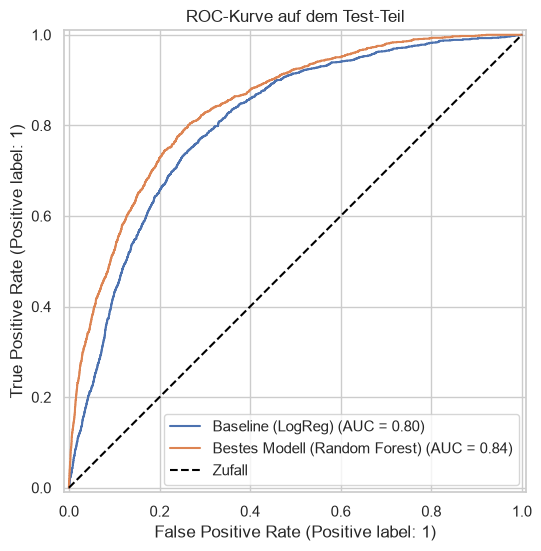

In [3]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, proba in probas.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], color="black", linestyle="--", label="Zufall")
ax.set_title("ROC-Kurve auf dem Test-Teil")
ax.legend()
plt.show()

Je weiter oben links, desto besser. Gestrichelt ist Raten.

Angenommen, die Kontrolleure schaffen 10 % der Kunden. Die erste Grafik zeigt, wie viele Betrüger man bei x % Kontrollen findet, danach kommt die Auswertung für genau die Top 10 %.

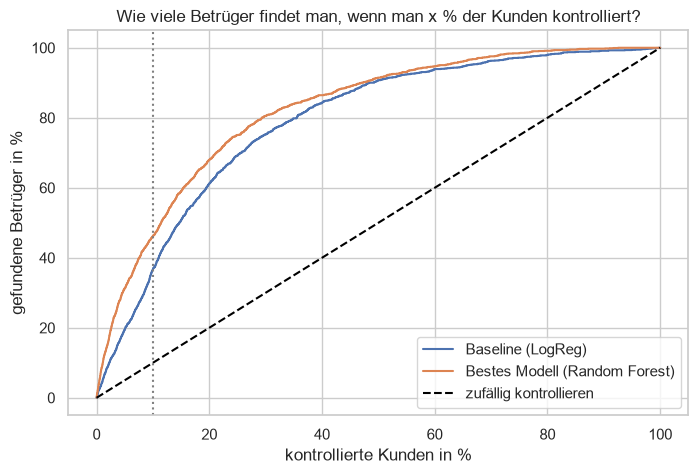

In [4]:
def gefundene_betrueger(y_true, proba):
    """Kunden nach Wahrscheinlichkeit sortieren: Anteil kontrolliert und Anteil gefundener Betrüger."""
    df_sort = pd.DataFrame({"target": list(y_true), "proba": list(proba)}).sort_values("proba", ascending=False)
    anteil_kontrolliert = np.arange(1, len(df_sort) + 1) / len(df_sort)
    anteil_gefunden = df_sort["target"].cumsum() / df_sort["target"].sum()
    return anteil_kontrolliert, anteil_gefunden


fig, ax = plt.subplots(figsize=(8, 5))
for name, proba in probas.items():
    x, y = gefundene_betrueger(y_test, proba)
    ax.plot(x * 100, y * 100, label=name)
ax.plot([0, 100], [0, 100], color="black", linestyle="--", label="zufällig kontrollieren")
ax.axvline(TOP_ANTEIL * 100, color="grey", linestyle=":")
ax.set_title("Wie viele Betrüger findet man, wenn man x % der Kunden kontrolliert?")
ax.set_xlabel("kontrollierte Kunden in %")
ax.set_ylabel("gefundene Betrüger in %")
ax.legend()
plt.show()

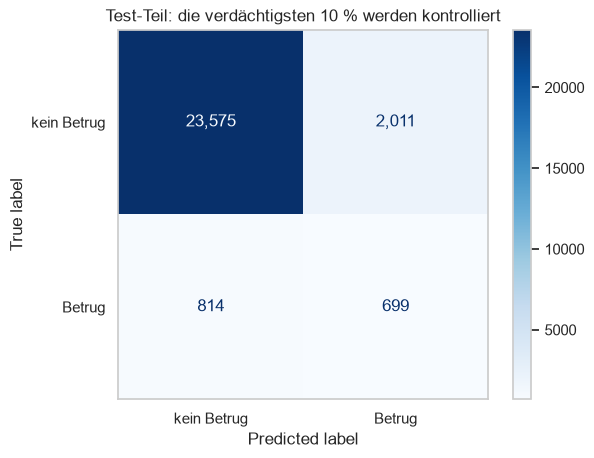

Kontrollen:        2,710
davon Betrüger:    699 (25.8%)
zufällig erwartet: 151 (5.6%)


In [5]:
# die verdächtigsten 10 % bekommen eine 1
schwelle = np.quantile(proba_best, 1 - TOP_ANTEIL)
vorhersage = (proba_best >= schwelle).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, vorhersage, display_labels=["kein Betrug", "Betrug"],
                                        cmap="Blues", values_format=",")
plt.title("Test-Teil: die verdächtigsten 10 % werden kontrolliert")
plt.grid(False)
plt.show()

kontrollen = vorhersage.sum()
treffer = ((vorhersage == 1) & (y_test == 1)).sum()
print(f"Kontrollen:        {kontrollen:,}")
print(f"davon Betrüger:    {treffer:,} ({treffer / kontrollen:.1%})")
print(f"zufällig erwartet: {kontrollen * y_test.mean():,.0f} ({y_test.mean():.1%})")

Bei 2.710 Kontrollen finde ich mit dem Modell 699 Betrüger, zufällig wären es nur etwa 151. Das sind 46 % aller Betrüger, mit der Baseline 37 %.

Fazit

Knapp die Hälfte aller Betrüger bei 10 % Kontrollen, und etwa jede vierte Kontrolle ist ein Treffer. Random Forest: ROC-AUC 0,841, Lift 4,61. Baseline: 0,805 und 3,66. Betrugsquote in den Top 10 % also 25,8 % gegenüber 20,5 %.

Grenzen für die Präsentation: target heißt erwischt, nicht betrogen. Das Modell hängt stark an der Anzahl der Zähler, was zum Teil Folge vom Erwischen sein könnte. Neue Kunden und Kunden mit nur einem Zähler erkennt es schlecht.